# Brain Tumor MRI Classification — Custom CNN (100 Epochs)


Found 2144 images belonging to 3 classes.
Found 458 images belonging to 3 classes.
Found 462 images belonging to 3 classes.


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


67/67 - 216s - 3s/step - accuracy: 0.7248 - loss: 1.5493 - val_accuracy: 0.2489 - val_loss: 3.3929
Epoch 2/100
67/67 - 198s - 3s/step - accuracy: 0.8438 - loss: 0.3960 - val_accuracy: 0.2729 - val_loss: 5.7141
Epoch 3/100
67/67 - 194s - 3s/step - accuracy: 0.8913 - loss: 0.2731 - val_accuracy: 0.4913 - val_loss: 4.5595
Epoch 4/100
67/67 - 191s - 3s/step - accuracy: 0.9039 - loss: 0.2313 - val_accuracy: 0.4738 - val_loss: 3.9555
Epoch 5/100
67/67 - 188s - 3s/step - accuracy: 0.9230 - loss: 0.1914 - val_accuracy: 0.5044 - val_loss: 3.8567
Epoch 6/100
67/67 - 189s - 3s/step - accuracy: 0.9333 - loss: 0.1613 - val_accuracy: 0.6725 - val_loss: 1.7002
Epoch 7/100
67/67 - 189s - 3s/step - accuracy: 0.9632 - loss: 0.1070 - val_accuracy: 0.7467 - val_loss: 0.7829
Epoch 8/100
67/67 - 187s - 3s/step - accuracy: 0.9674 - loss: 0.0875 - val_accuracy: 0.8603 - val_loss: 0.3682
Epoch 9/100
67/67 - 187s - 3s/step - accuracy: 0.9785 - loss: 0.0666 - val_accuracy: 0.8886 - val_loss: 0.3104
Epoch 10/100


Epoch 75/100
67/67 - 195s - 3s/step - accuracy: 0.9916 - loss: 0.0242 - val_accuracy: 0.9279 - val_loss: 0.5760
Epoch 76/100
67/67 - 202s - 3s/step - accuracy: 0.9939 - loss: 0.0168 - val_accuracy: 0.9476 - val_loss: 0.4771
Epoch 77/100
67/67 - 195s - 3s/step - accuracy: 0.9930 - loss: 0.0166 - val_accuracy: 0.9301 - val_loss: 0.5011
Epoch 78/100
67/67 - 197s - 3s/step - accuracy: 0.9972 - loss: 0.0123 - val_accuracy: 0.9454 - val_loss: 0.4187
Epoch 79/100
67/67 - 190s - 3s/step - accuracy: 0.9958 - loss: 0.0097 - val_accuracy: 0.9367 - val_loss: 0.5055
Epoch 80/100
67/67 - 189s - 3s/step - accuracy: 0.9953 - loss: 0.0117 - val_accuracy: 0.9367 - val_loss: 0.5223
Epoch 81/100
67/67 - 188s - 3s/step - accuracy: 0.9967 - loss: 0.0133 - val_accuracy: 0.9454 - val_loss: 0.5305
Epoch 82/100
67/67 - 189s - 3s/step - accuracy: 0.9986 - loss: 0.0037 - val_accuracy: 0.9520 - val_loss: 0.5028
Epoch 83/100
67/67 - 188s - 3s/step - accuracy: 0.9981 - loss: 0.0047 - val_accuracy: 0.9520 - val_loss:

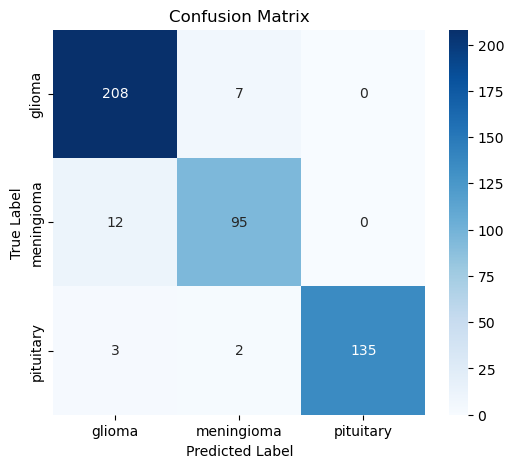

Precision-Recall AUC for class 2: 0.99


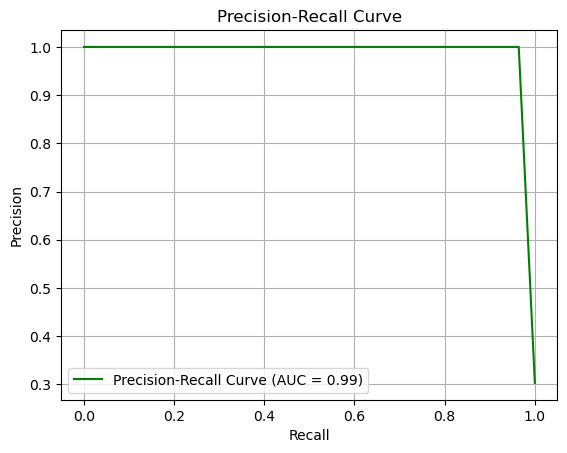

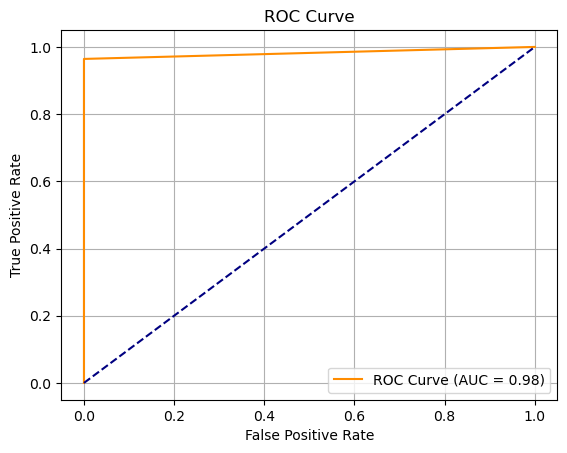

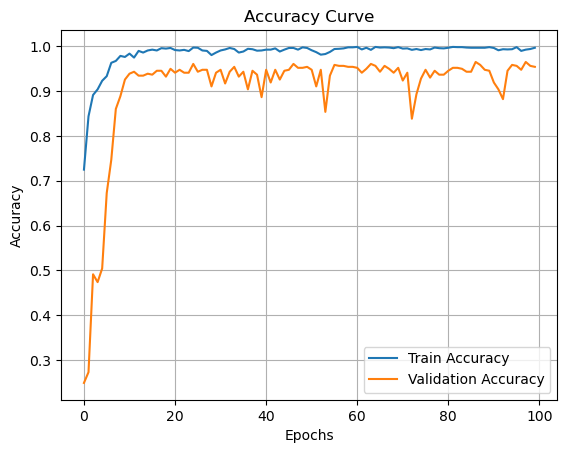

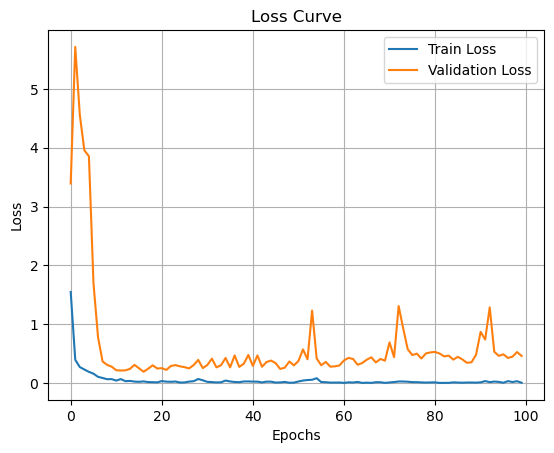

Model saved successfully!


In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_curve, roc_curve, auc
import seaborn as sns
import os

# Base data directory
base_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'

# Paths
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

# Image parameters
img_height, img_width = 224, 224
batch_size = 32

# ImageDataGenerator
datagen = ImageDataGenerator(rescale=1./255)

train_data = datagen.flow_from_directory(train_dir, target_size=(img_height, img_width),
                                         batch_size=batch_size, class_mode='categorical', shuffle=True)
val_data = datagen.flow_from_directory(val_dir, target_size=(img_height, img_width),
                                       batch_size=batch_size, class_mode='categorical', shuffle=True)
test_data = datagen.flow_from_directory(test_dir, target_size=(img_height, img_width),
                                        batch_size=batch_size, class_mode='categorical', shuffle=False)

# Build CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(img_height, img_width, 3)),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(3, activation='softmax')  # 3 output classes
])

# Compile model
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train model for exactly 20 epochs (no early stopping)
history = model.fit(train_data,
                    epochs=100,
                    validation_data=val_data,
                    verbose=2)

# Evaluate on test data
test_loss, test_acc = model.evaluate(test_data)
print(f"\nTest Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# Predictions
test_labels = test_data.classes
test_preds = model.predict(test_data)
test_preds_labels = np.argmax(test_preds, axis=1)

# Confusion matrix and classification report
conf_matrix = confusion_matrix(test_labels, test_preds_labels)
print("\nConfusion Matrix:")
print(conf_matrix)

print("\nClassification Report:")
print(classification_report(test_labels, test_preds_labels, target_names=test_data.class_indices.keys()))

# Confusion matrix plot
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_data.class_indices.keys(),
            yticklabels=test_data.class_indices.keys())
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Precision-Recall and ROC for class 2 (change if needed)
class_index = 2
precision, recall, _ = precision_recall_curve(test_labels == class_index, test_preds_labels == class_index)
pr_auc = auc(recall, precision)
print(f"Precision-Recall AUC for class {class_index}: {pr_auc:.2f}")

plt.figure()
plt.plot(recall, precision, label=f'Precision-Recall Curve (AUC = {pr_auc:.2f})', color='green')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)
plt.show()

fpr, tpr, _ = roc_curve(test_labels == class_index, test_preds_labels == class_index)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})', color='darkorange')
plt.plot([0, 1], [0, 1], linestyle='--', color='navy')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

# Accuracy and Loss plots
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [3]:
model.save('CNN model_100 Epochs.h5')  # Save the model
print("Model saved successfully!")

Model saved successfully!


In [1]:
import time
import os
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# === PATHS ===
model_path = r"C:\Users\usER\Downloads\CNN model_100 Epochs.h5"
image_path = r"C:\Users\usER\Downloads\1512427\converted_images_split\test\glioma\3061.jpg"

# === Load Model ===
model = load_model(model_path)
print("✅ Model loaded successfully.")

# === Load and Preprocess Image ===
img = load_img(image_path, target_size=(224, 224))  # adjust to your model input
img_array = img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)  # shape: (1, 224, 224, 3)

# === Measure Inference Time ===
start = time.time()
_ = model.predict(img_array)
end = time.time()

inference_time_ms = (end - start) * 1000
print(f"🕒 Inference Time: {inference_time_ms:.2f} ms")

# === Measure Model Size ===
model_size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"💾 Model Size: {model_size_mb:.2f} MB")


✅ Model loaded successfully.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 373ms/step
🕒 Inference Time: 493.52 ms
💾 Model Size: 254.66 MB


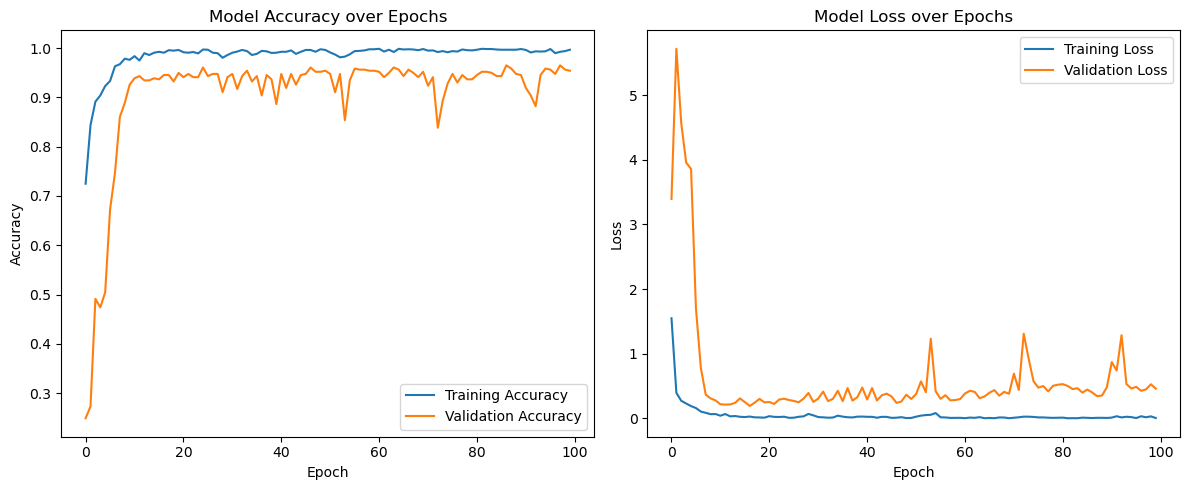

In [4]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot training & validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()



Found 462 images belonging to 3 classes.


C:\Users\usER\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 402ms/step

Classification Report:
              precision    recall  f1-score   support

      glioma       0.93      0.97      0.95       215
  meningioma       0.91      0.89      0.90       107
   pituitary       1.00      0.96      0.98       140

    accuracy                           0.95       462
   macro avg       0.95      0.94      0.94       462
weighted avg       0.95      0.95      0.95       462



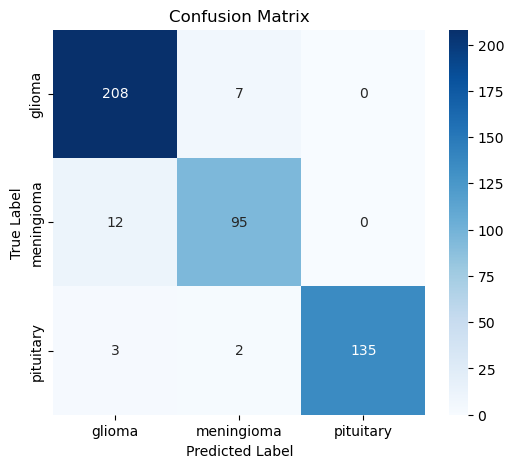

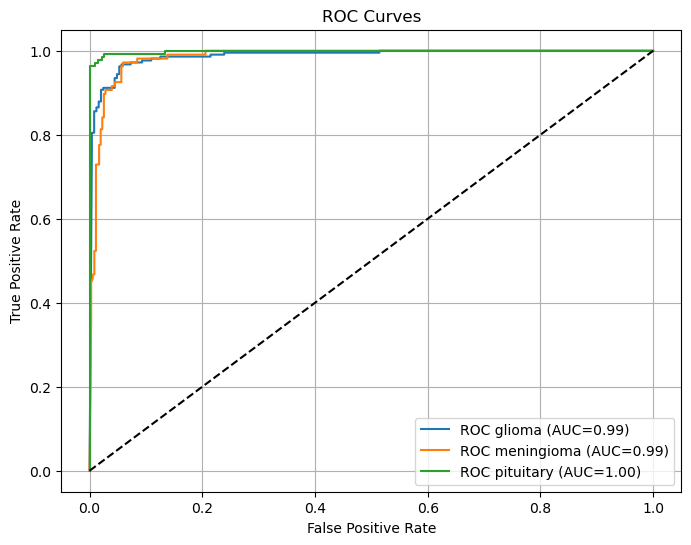

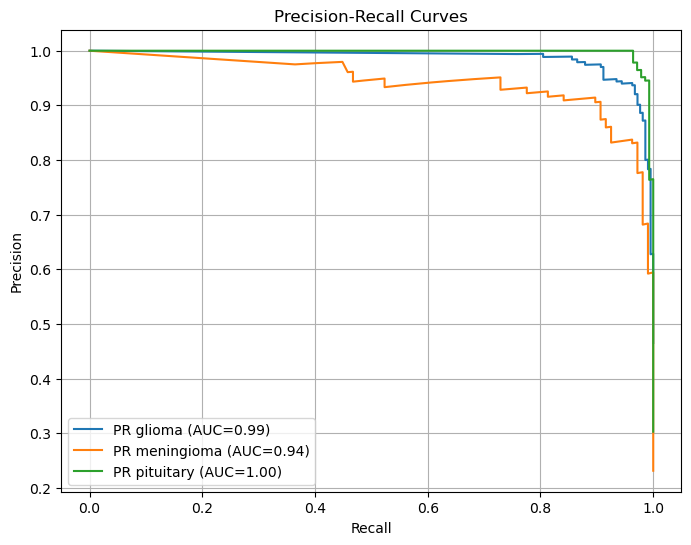

In [5]:
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.preprocessing import label_binarize
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load model
model = load_model('CNN model_100 Epochs.h5')

# Data setup
base_dir = r'C:\Users\usER\Downloads\1512427\converted_images_split'
test_dir = os.path.join(base_dir, 'test')
img_height, img_width = 224, 224
batch_size = 32

datagen = ImageDataGenerator(rescale=1./255)
test_data = datagen.flow_from_directory(test_dir, target_size=(img_height, img_width),
                                        batch_size=batch_size, class_mode='categorical', shuffle=False)

test_labels = test_data.classes
class_names = list(test_data.class_indices.keys())
n_classes = len(class_names)

# Predictions
test_preds = model.predict(test_data)
test_preds_labels = np.argmax(test_preds, axis=1)

# Confusion matrix & report (optional)
from sklearn.metrics import confusion_matrix, classification_report
conf_matrix = confusion_matrix(test_labels, test_preds_labels)
print("\nClassification Report:")
print(classification_report(test_labels, test_preds_labels, target_names=class_names))

# Plot Confusion Matrix (optional)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Binarize labels for multi-class metrics
y_true_bin = label_binarize(test_labels, classes=range(n_classes))

# ROC Curve and AUC per class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], test_preds[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f'ROC {class_names[i]} (AUC={roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curves')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Precision-Recall Curve and AUC per class
precision = dict()
recall = dict()
pr_auc = dict()
for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], test_preds[:, i])
    pr_auc[i] = auc(recall[i], precision[i])

plt.figure(figsize=(8, 6))
for i in range(n_classes):
    plt.plot(recall[i], precision[i], label=f'PR {class_names[i]} (AUC={pr_auc[i]:.2f})')
plt.title('Precision-Recall Curves')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()

